<a href="https://colab.research.google.com/github/Pappas313/Computational-vision/blob/main/Advanced_Financial_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Advanced Financial Data Analytics with Python**

We'll build a complete Financial Transaction Analytics & Fraud Detection project in Google Colab, using NumPy, Pandas, PySpark, Xarray, Matplotlib, Seaborn, Scikit-learn, and Spark SQL.

Open Google Colab, select New notebook, and add each code block below as a separate code cell using + Code. Run the cells in order with Shift + Enter.

**Step 1 — Install the libraries**

In [15]:

%pip install -q numpy pandas pyarrow pyspark xarray \
    matplotlib seaborn scikit-learn netCDF4


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 57.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 43.6 MB/s eta 0:00:00


This installs the libraries needed for the project. If Colab asks you to restart the runtime, restart it and continue from Step 2.

**Step 2 — Import libraries and configure the project**

In [16]:

import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    ConfusionMatrixDisplay
)

os.makedirs("output", exist_ok=True)

RANDOM_STATE = 42
N_TRANSACTIONS = 20_000

rng = np.random.default_rng(RANDOM_STATE)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Xarray:", xr.__version__)


Pandas: 2.2.3
NumPy: 2.1.3
Xarray: 2025.12.0


**Step 3 — Generate synthetic financial transactions**

We'll create transactions with customer IDs, timestamps, countries, merchant categories, amounts, and device risk indicators.

In [17]:

countries = ["GR", "DE", "FR", "IT", "ES"]
categories = [
    "Retail", "Travel", "Electronics",
    "Groceries", "Gaming"
]

n = N_TRANSACTIONS

transactions = pd.DataFrame({
    "transaction_id": np.arange(1, n + 1),
    "customer_id": rng.integers(1, 2001, n),
    "timestamp": (
        pd.Timestamp("2025-01-01")
        + pd.to_timedelta(
            rng.integers(0, 365 * 24 * 60, n),
            unit="m"
        )
    ),
    "country": rng.choice(countries, n),
    "merchant_category": rng.choice(categories, n),
    "amount": np.round(
        rng.lognormal(3.8, 1.1, n), 2
    ),
    "is_foreign": rng.binomial(1, 0.12, n),
    "device_risk": rng.beta(2, 8, n)
})

# Simulated fraud probability
logit = (
    -5.0
    + 0.75 * (transactions["amount"] > 300)
    + 1.2 * transactions["is_foreign"]
    + 3.0 * transactions["device_risk"]
)

fraud_probability = 1 / (1 + np.exp(-logit))

transactions["is_fraud"] = rng.binomial(
    1, fraud_probability
)

transactions.to_parquet(
    "output/transactions.parquet",
    index=False
)

display(transactions.head())

print("Transactions:", len(transactions))
print("Fraud rate:", transactions["is_fraud"].mean())


,transaction_id,customer_id,timestamp,country,merchant_category,amount,is_foreign,device_risk,is_fraud
0,1,179,2025-01-13 11:14:00,ES,Retail,87.36,0,0.198401,0
1,2,1548,2025-09-21 01:34:00,IT,Travel,2.06,1,0.118151,0
2,3,1310,2025-03-20 02:16:00,DE,Groceries,117.11,0,0.173180,0
3,4,878,2025-09-17 14:26:00,ES,Electronics,35.54,0,0.068338,0
4,5,867,2025-07-26 01:43:00,ES,Retail,12.73,0,0.080493,0


Transactions: 20000
Fraud rate: 0.01815


**Step 3 — Generate synthetic financial transactions**

We'll create transactions with customer IDs, timestamps, countries, merchant categories, amounts, and device risk indicators.

In [18]:

countries = ["GR", "DE", "FR", "IT", "ES"]
categories = [
    "Retail", "Travel", "Electronics",
    "Groceries", "Gaming"
]

n = N_TRANSACTIONS

transactions = pd.DataFrame({
    "transaction_id": np.arange(1, n + 1),
    "customer_id": rng.integers(1, 2001, n),
    "timestamp": (
        pd.Timestamp("2025-01-01")
        + pd.to_timedelta(
            rng.integers(0, 365 * 24 * 60, n),
            unit="m"
        )
    ),
    "country": rng.choice(countries, n),
    "merchant_category": rng.choice(categories, n),
    "amount": np.round(
        rng.lognormal(3.8, 1.1, n), 2
    ),
    "is_foreign": rng.binomial(1, 0.12, n),
    "device_risk": rng.beta(2, 8, n)
})

# Simulated fraud probability
logit = (
    -5.0
    + 0.75 * (transactions["amount"] > 300)
    + 1.2 * transactions["is_foreign"]
    + 3.0 * transactions["device_risk"]
)

fraud_probability = 1 / (1 + np.exp(-logit))

transactions["is_fraud"] = rng.binomial(
    1, fraud_probability
)

transactions.to_parquet(
    "output/transactions.parquet",
    index=False
)

display(transactions.head())

print("Transactions:", len(transactions))
print("Fraud rate:", transactions["is_fraud"].mean())


,transaction_id,customer_id,timestamp,country,merchant_category,amount,is_foreign,device_risk,is_fraud
0,1,114,2025-05-16 03:41:00,FR,Gaming,76.20,0,0.043576,0
1,2,1183,2025-06-26 23:11:00,ES,Travel,108.52,0,0.314758,0
2,3,699,2025-06-20 02:39:00,FR,Gaming,157.44,0,0.299246,0
3,4,1285,2025-04-02 03:13:00,GR,Groceries,190.63,0,0.106073,0
4,5,694,2025-02-16 05:05:00,ES,Travel,312.99,0,0.125799,0


Transactions: 20000
Fraud rate: 0.01765


**Step 4 — Start PySpark and load the data**

In [20]:
import pandas as pd

# Fix: Convert pandas timestamp column to microsecond resolution ('us') to ensure PySpark compatibility
transactions_df = pd.read_parquet("output/transactions.parquet")
transactions_df["timestamp"] = transactions_df["timestamp"].astype("datetime64[us]")
transactions_df.to_parquet("output/transactions.parquet", index=False, coerce_timestamps="us")

# Re-initialize Spark Session and read the microsecond-compatible Parquet file
spark = (
    SparkSession.builder
    .appName("FinancialRiskAnalytics")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

spark_df = spark.read.parquet(
    "output/transactions.parquet"
)

spark_df.printSchema()
spark_df.show(5, truncate=False)

root
 |-- transaction_id: long (nullable = true)
 |-- customer_id: long (nullable = true)
 |-- timestamp: timestamp_ntz (nullable = true)
 |-- country: string (nullable = true)
 |-- merchant_category: string (nullable = true)
 |-- amount: double (nullable = true)
 |-- is_foreign: long (nullable = true)
 |-- device_risk: double (nullable = true)
 |-- is_fraud: long (nullable = true)

+--------------+-----------+-------------------+-------+-----------------+------+----------+-------------------+--------+
|transaction_id|customer_id|timestamp          |country|merchant_category|amount|is_foreign|device_risk        |is_fraud|
+--------------+-----------+-------------------+-------+-----------------+------+----------+-------------------+--------+
|1             |114        |2025-05-16 03:41:00|FR     |Gaming           |76.2  |0         |0.04357640216793554|0       |
|2             |1183       |2025-06-26 23:11:00|ES     |Travel           |108.52|0         |0.31475774659165545|0       |
|3  

**Step 5 — Clean data using PySpark**

In [21]:

clean_df = (
    spark_df
    .dropDuplicates(["transaction_id"])
    .filter(F.col("amount") > 0)
    .filter(F.col("customer_id").isNotNull())
    .filter(F.col("timestamp").isNotNull())
)

clean_df = clean_df.withColumn(
    "timestamp",
    F.col("timestamp").cast("timestamp")
)

print("Clean transactions:", clean_df.count())


Clean transactions: 20000


**Step 6 — Advanced feature engineering with Spark window functions**

We'll calculate historical customer spending and transaction velocity. These features use prior transactions rather than future information.

In [22]:

history_window = (
    Window.partitionBy("customer_id")
    .orderBy("timestamp", "transaction_id")
    .rowsBetween(Window.unboundedPreceding, -1)
)

features_spark = (
    clean_df
    .withColumn(
        "previous_tx_count",
        F.count("transaction_id").over(history_window)
    )
    .withColumn(
        "previous_avg_amount",
        F.avg("amount").over(history_window)
    )
)

features_spark = features_spark.withColumn(
    "amount_vs_history",
    F.when(
        F.col("previous_avg_amount") > 0,
        F.col("amount") / F.col("previous_avg_amount")
    ).otherwise(1.0)
)

# Count transactions in previous 24 hours
# This includes same-timestamp records in the count.
time_window = (
    Window.partitionBy("customer_id")
    .orderBy(F.col("timestamp").cast("long"))
    .rangeBetween(-86400, -1)
)

features_spark = features_spark.withColumn(
    "transactions_last_24h",
    F.count("*").over(time_window)
)

features_spark.select(
    "customer_id",
    "amount",
    "previous_tx_count",
    "previous_avg_amount",
    "transactions_last_24h"
).show(10)


+-----------+------+-----------------+-------------------+---------------------+
|customer_id|amount|previous_tx_count|previous_avg_amount|transactions_last_24h|
+-----------+------+-----------------+-------------------+---------------------+
|          1| 25.19|                0|               NULL|                    0|
|          1| 62.74|                1|              25.19|                    0|
|          1|  5.91|                2|             43.965|                    1|
|          1|171.14|                3|              31.28|                    0|
|          1| 43.37|                4|             66.245|                    0|
|          1|  8.36|                5|              61.67|                    0|
|          1| 45.37|                6| 52.785000000000004|                    0|
|          1| 15.14|                7|  51.72571428571429|                    0|
|          2| 86.03|                0|               NULL|                    0|
|          2| 84.59|        

The 24-hour range excludes transactions sharing the exact current timestamp. For real-time production scoring, you would also need to define how simultaneous events and late-arriving transactions are handled.

**Step 7 — Convert aggregated Spark data to Pandas**

For this small educational dataset, we can safely collect the feature data into Pandas.

In [23]:

features = features_spark.toPandas()

features["timestamp"] = pd.to_datetime(
    features["timestamp"]
)

features = features.sort_values(
    ["timestamp", "transaction_id"]
).reset_index(drop=True)

print(features.shape)
display(features.head())


(20000, 13)


,transaction_id,customer_id,timestamp,country,merchant_category,amount,is_foreign,device_risk,is_fraud,previous_tx_count,previous_avg_amount,amount_vs_history,transactions_last_24h
0,7643,578,2025-01-01 00:15:00,GR,Groceries,25.73,0,0.449762,0,0,NaN,1.0,0
1,14404,1307,2025-01-01 00:16:00,IT,Retail,21.74,1,0.221953,0,0,NaN,1.0,0
2,5272,652,2025-01-01 00:30:00,DE,Retail,53.91,0,0.066977,0,0,NaN,1.0,0
3,10796,1643,2025-01-01 00:55:00,IT,Gaming,81.10,0,0.107283,0,0,NaN,1.0,0
4,4118,164,2025-01-01 01:19:00,IT,Electronics,311.15,0,0.035239,0,0,NaN,1.0,0


**Step 8 — Statistical analytics with NumPy and Pandas**

In [24]:

features["hour"] = features["timestamp"].dt.hour
features["day_of_week"] = features["timestamp"].dt.dayofweek
features["is_weekend"] = (
    features["day_of_week"] >= 5
).astype(int)

features["log_amount"] = np.log1p(
    features["amount"]
)

q1 = features["amount"].quantile(0.25)
q3 = features["amount"].quantile(0.75)
iqr = q3 - q1

features["is_amount_outlier"] = (
    features["amount"] > q3 + 1.5 * iqr
).astype(int)

summary = features.groupby(
    "merchant_category"
).agg(
    transactions=("transaction_id", "count"),
    fraud_cases=("is_fraud", "sum"),
    average_amount=("amount", "mean"),
    total_volume=("amount", "sum")
)

summary["fraud_rate"] = (
    summary["fraud_cases"] / summary["transactions"]
)

display(summary.sort_values(
    "fraud_rate", ascending=False
))


,transactions,fraud_cases,average_amount,total_volume,fraud_rate
merchant_category,,,,,
Electronics,3911,80,84.142380,329080.85,0.020455
Travel,3980,76,81.021824,322466.86,0.019095
Gaming,4070,70,80.345796,327007.39,0.017199
Groceries,4018,64,80.272576,322535.21,0.015928
Retail,4021,63,85.178580,342503.07,0.015668


**Step 9 — Multidimensional analytics with Xarray**

Create a data cube using three dimensions: month, country, and merchant category.

In [25]:

features["month"] = (
    features["timestamp"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

cube_df = features.groupby(
    ["month", "country", "merchant_category"]
).agg(
    transactions=("transaction_id", "count"),
    fraud_cases=("is_fraud", "sum"),
    volume=("amount", "sum")
)

cube = cube_df.to_xarray().fillna(0)

cube["fraud_rate"] = xr.where(
    cube["transactions"] > 0,
    cube["fraud_cases"] / cube["transactions"],
    np.nan
)

display(cube)

# Fraud rate by country
country_fraud = (
    cube["fraud_cases"].sum(
        dim=["month", "merchant_category"]
    )
    /
    cube["transactions"].sum(
        dim=["month", "merchant_category"]
    )
)

print(country_fraud)

cube.to_netcdf("output/analytics_cube.nc")


<xarray.Dataset> Size: 10kB
Dimensions:            (month: 12, country: 5, merchant_category: 5)
Coordinates:
  * month              (month) datetime64[ns] 96B 2025-01-01 ... 2025-12-01
  * country            (country) object 40B 'DE' 'ES' 'FR' 'GR' 'IT'
  * merchant_category  (merchant_category) object 40B 'Electronics' ... 'Travel'
Data variables:
    transactions       (month, country, merchant_category) int64 2kB 79 ... 62
    fraud_cases        (month, country, merchant_category) int64 2kB 3 2 ... 2 3
    volume             (month, country, merchant_category) float64 2kB 7.526e...
    fraud_rate         (month, country, merchant_category) float64 2kB 0.0379...

<xarray.DataArray (country: 5)> Size: 40B
array([0.01927466, 0.01825   , 0.01615346, 0.01795511, 0.01664627])
Coordinates:
  * country  (country) object 40B 'DE' 'ES' 'FR' 'GR' 'IT'


**Step 10 — Train a fraud detection model**

We will use a chronological split: the earliest 80% of transactions for training and the latest 20% for testing.

In [26]:

numeric_cols = [
    "amount",
    "is_foreign",
    "device_risk",
    "previous_tx_count",
    "previous_avg_amount",
    "amount_vs_history",
    "transactions_last_24h",
    "hour",
    "day_of_week"
]

categorical_cols = [
    "country",
    "merchant_category"
]

feature_cols = numeric_cols + categorical_cols

split = int(len(features) * 0.8)

train = features.iloc[:split]
test = features.iloc[split:]

preprocessor = ColumnTransformer([
    (
        "numeric",
        SimpleImputer(strategy="median"),
        numeric_cols
    ),
    (
        "categorical",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ),
        categorical_cols
    )
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.05,
        max_leaf_nodes=31,
        random_state=RANDOM_STATE
    ))
])

model.fit(
    train[feature_cols],
    train["is_fraud"]
)

probabilities = model.predict_proba(
    test[feature_cols]
)[:, 1]

predictions = (
    probabilities >= 0.5
).astype(int)

print(classification_report(
    test["is_fraud"],
    predictions,
    zero_division=0
))

print(
    "PR-AUC:",
    average_precision_score(
        test["is_fraud"], probabilities
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        test["is_fraud"], probabilities
    )
)


              precision    recall  f1-score   support

           0       0.98      1.00      0.99      3931
           1       0.00      0.00      0.00        69

    accuracy                           0.98      4000
   macro avg       0.49      0.50      0.50      4000
weighted avg       0.97      0.98      0.97      4000

PR-AUC: 0.040565582859344994
ROC-AUC: 0.6267609009028938


**Step 10 — Train a fraud detection model**

We will use a chronological split: the earliest 80% of transactions for training and the latest 20% for testing.

In [27]:

numeric_cols = [
    "amount",
    "is_foreign",
    "device_risk",
    "previous_tx_count",
    "previous_avg_amount",
    "amount_vs_history",
    "transactions_last_24h",
    "hour",
    "day_of_week"
]

categorical_cols = [
    "country",
    "merchant_category"
]

feature_cols = numeric_cols + categorical_cols

split = int(len(features) * 0.8)

train = features.iloc[:split]
test = features.iloc[split:]

preprocessor = ColumnTransformer([
    (
        "numeric",
        SimpleImputer(strategy="median"),
        numeric_cols
    ),
    (
        "categorical",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ),
        categorical_cols
    )
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.05,
        max_leaf_nodes=31,
        random_state=RANDOM_STATE
    ))
])

model.fit(
    train[feature_cols],
    train["is_fraud"]
)

probabilities = model.predict_proba(
    test[feature_cols]
)[:, 1]

predictions = (
    probabilities >= 0.5
).astype(int)

print(classification_report(
    test["is_fraud"],
    predictions,
    zero_division=0
))

print(
    "PR-AUC:",
    average_precision_score(
        test["is_fraud"], probabilities
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        test["is_fraud"], probabilities
    )
)


              precision    recall  f1-score   support

           0       0.98      1.00      0.99      3931
           1       0.00      0.00      0.00        69

    accuracy                           0.98      4000
   macro avg       0.49      0.50      0.50      4000
weighted avg       0.97      0.98      0.97      4000

PR-AUC: 0.040565582859344994
ROC-AUC: 0.6267609009028938


**Step 11 — Visualize results with Matplotlib and Seaborn**

Chart A — Fraud detection precision-recall curve

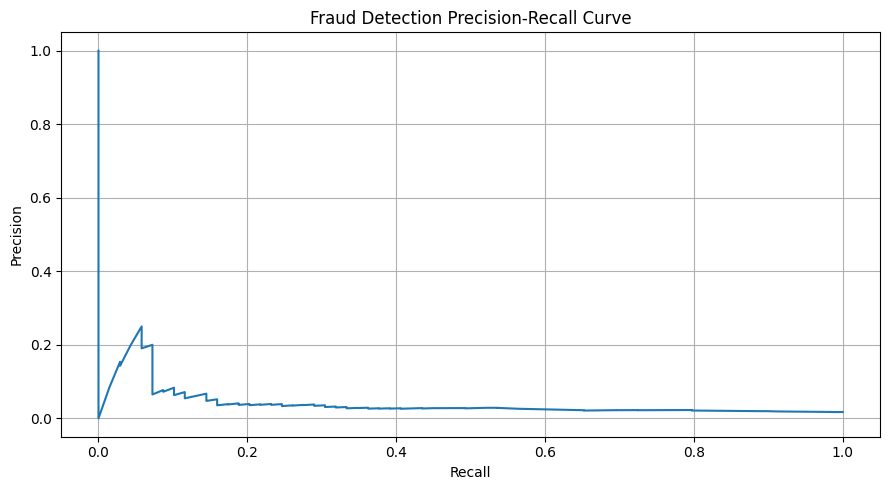

In [28]:

precision, recall, thresholds = precision_recall_curve(
    test["is_fraud"],
    probabilities
)

plt.figure(figsize=(9, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Fraud Detection Precision-Recall Curve")
plt.grid(True)
plt.tight_layout()
plt.savefig("output/precision_recall.png")
plt.show()


**Chart B — Confusion matrix**

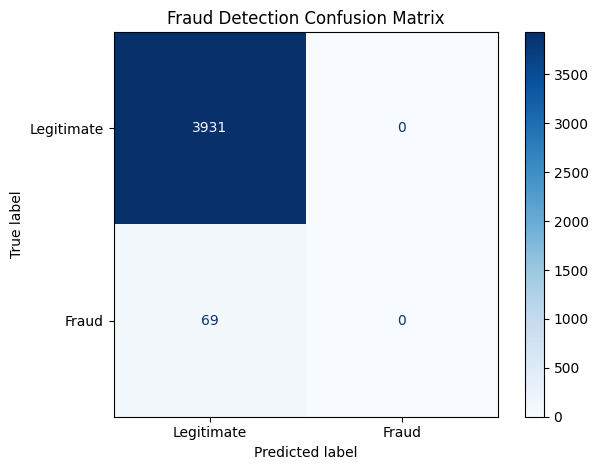

In [29]:

ConfusionMatrixDisplay.from_predictions(
    test["is_fraud"],
    predictions,
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues"
)

plt.title("Fraud Detection Confusion Matrix")
plt.tight_layout()
plt.savefig("output/confusion_matrix.png")
plt.show()


**Chart C — Transaction amount distribution**

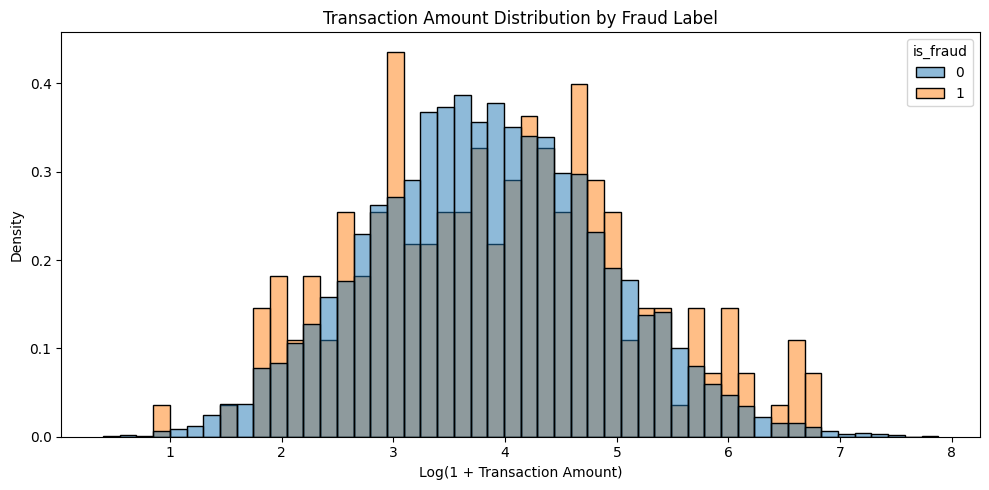

In [30]:

sample = features.sample(
    min(10000, len(features)),
    random_state=RANDOM_STATE
)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=sample,
    x="log_amount",
    hue="is_fraud",
    bins=50,
    stat="density",
    common_norm=False
)

plt.title("Transaction Amount Distribution by Fraud Label")
plt.xlabel("Log(1 + Transaction Amount)")
plt.tight_layout()
plt.savefig("output/amount_distribution.png")
plt.show()


**Step 12 — Run SQL analytics with Spark SQL**

PySpark allows you to execute SQL directly against Spark DataFrames.

In [31]:

clean_df.createOrReplaceTempView("transactions")

sql_result = spark.sql("""
    WITH daily AS (
        SELECT
            country,
            DATE(timestamp) AS transaction_date,
            COUNT(*) AS transactions,
            SUM(amount) AS total_amount,
            SUM(is_fraud) AS fraud_cases
        FROM transactions
        GROUP BY country, DATE(timestamp)
    )
    SELECT
        country,
        transaction_date,
        transactions,
        total_amount,
        fraud_cases,
        SUM(total_amount) OVER (
            PARTITION BY country
            ORDER BY transaction_date
            ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
        ) AS rolling_7_active_days_volume
    FROM daily
    ORDER BY country, transaction_date
""")

sql_result.show(20, truncate=False)


+-------+----------------+------------+------------------+-----------+----------------------------+
|country|transaction_date|transactions|total_amount      |fraud_cases|rolling_7_active_days_volume|
+-------+----------------+------------+------------------+-----------+----------------------------+
|DE     |2025-01-01      |16          |1032.0700000000002|1          |1032.0700000000002          |
|DE     |2025-01-02      |9           |634.4200000000001 |0          |1666.4900000000002          |
|DE     |2025-01-03      |9           |533.39            |0          |2199.88                     |
|DE     |2025-01-04      |15          |2506.15           |0          |4706.030000000001           |
|DE     |2025-01-05      |20          |1925.56           |1          |6631.59                     |
|DE     |2025-01-06      |7           |458.85            |0          |7090.4400000000005          |
|DE     |2025-01-07      |11          |789.85            |0          |7880.290000000001           |


This query calculates rolling transaction volume over seven active days per country.

**Step 13 — Export your results**

In [33]:

summary.to_csv("output/category_summary.csv")

test_results = test[[
    "transaction_id",
    "timestamp",
    "amount",
    "is_fraud"
]].copy()

test_results["fraud_probability"] = probabilities
test_results["predicted_fraud"] = predictions

test_results.to_csv(
    "output/model_predictions.csv",
    index=False
)

# Create downloadable ZIP
import shutil

shutil.make_archive(
    "financial_analytics_results",
    "zip",
    "output"
)

from google.colab import files

files.download("financial_analytics_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Step 14 — Stop Spark when finished**

In [34]:

spark.stop()
print("Analytics pipeline completed.")


Analytics pipeline completed.


What you've built

You now have an end-to-end analytics workflow covering:
- Synthetic transaction generation with NumPy.
- Distributed ETL and window functions with PySpark.
- Business statistics and feature engineering with Pandas.
- Multidimensional aggregation with Xarray.
- Fraud classification with Scikit-learn.
- Model evaluation and visualizations with Matplotlib and Seaborn.
- SQL analytical queries using Spark SQL.
- CSV, Parquet, NetCDF, and PNG exports.

**Important:** This is a learning project using simulated fraud labels, not a validated financial fraud detection system. The default classification threshold and model performance should not be used for real transaction decisions.

**Advanced Financial Analytics — Additional Diagrams, Visualizations & Notes**

Let's extend your existing Google Colab Financial Risk Analytics project with more advanced diagrams, statistical charts, and explanations.

These examples continue from the previous notebook. Run them after Step 14, when features, test, test_probs, test_predictions, cube, and model are available.

We'll add 10 visualizations covering transaction patterns, customer behavior, fraud risk, and machine learning.

**Diagram 1 — Financial analytics architecture**

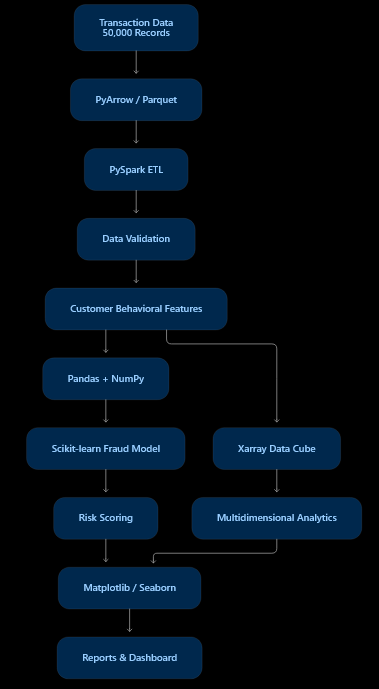

**Notes: **PySpark handles data processing, Pandas and NumPy support statistical analysis, Xarray organizes multidimensional metrics, and Scikit-learn predicts fraud risk. In production, large-scale feature preparation should remain distributed rather than collecting all records into Pandas.

**Diagram 2 — Monthly transaction volume**

This chart shows how transaction volume changes throughout the year.

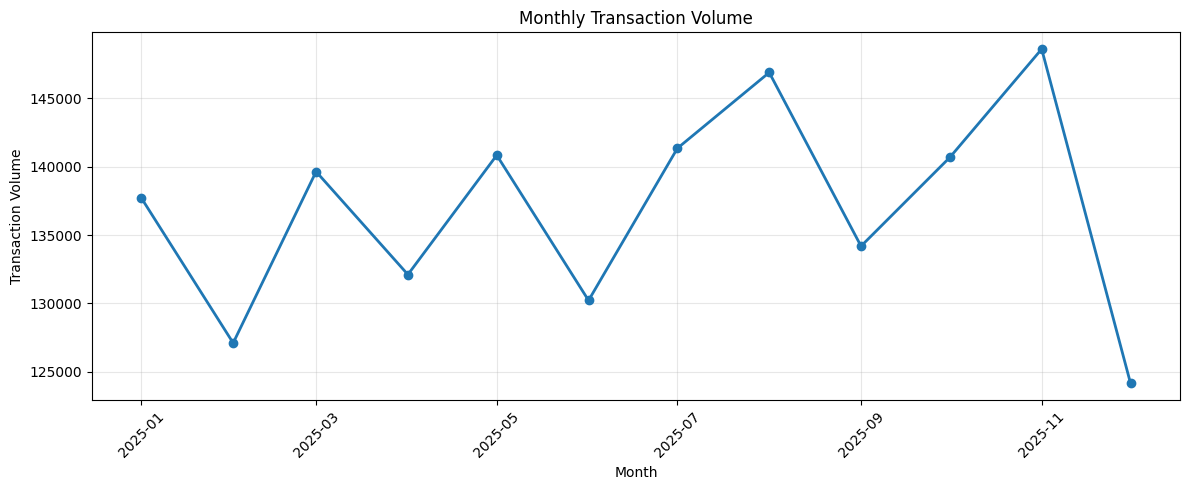

In [35]:

monthly = (
    features.groupby("month")
    .agg(
        volume=("amount", "sum"),
        transactions=("transaction_id", "count")
    )
    .sort_index()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly.index,
    monthly["volume"],
    marker="o",
    linewidth=2
)

ax.set_title("Monthly Transaction Volume")
ax.set_xlabel("Month")
ax.set_ylabel("Transaction Volume")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Interpretation:** Look for seasonality, unexpected spikes, and declines. Since the notebook generates random synthetic transactions without an explicit growth trend, the actual chart should not be expected to show steady growth.

**Diagram 3 — Fraud rate by merchant category**

We want to understand whether certain merchant categories experience more fraud than others.

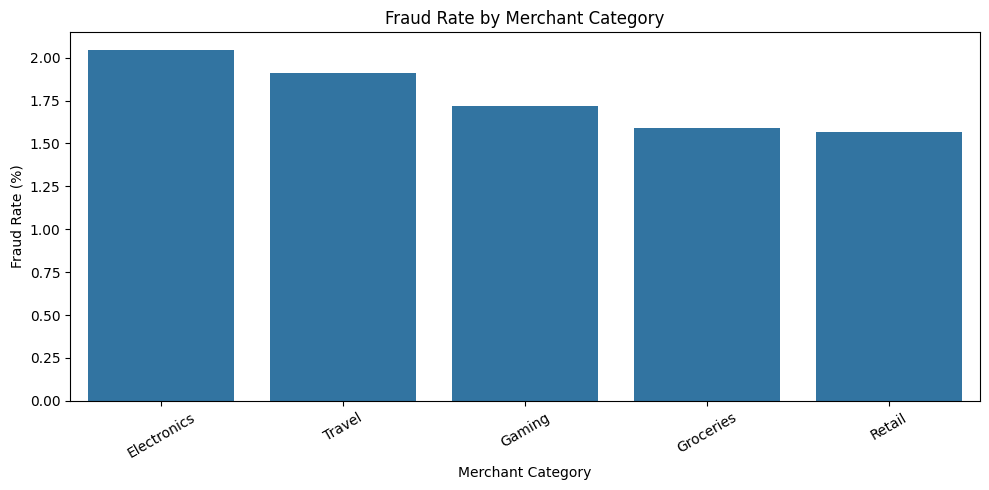

In [36]:

category_risk = (
    features.groupby("merchant_category")["is_fraud"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=category_risk.index,
    y=category_risk.values
)

plt.title("Fraud Rate by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Notes:** In this synthetic dataset, merchant category is not part of the fraud-generation formula. Any observed differences are mostly sampling variation or incidental correlations. A higher fraud rate alone does not prove that a category causes fraud.

**Diagram 4 — Fraud patterns by hour of day**

This chart helps identify whether fraud rates vary by transaction hour.

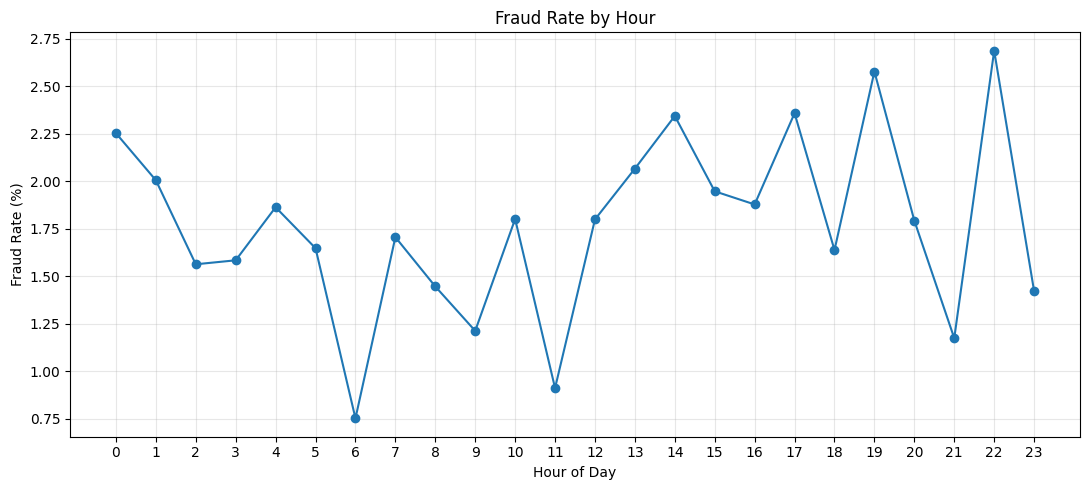

In [37]:

hourly_risk = (
    features.groupby("hour")
    .agg(
        transactions=("transaction_id", "count"),
        fraud_cases=("is_fraud", "sum")
    )
)

hourly_risk["fraud_rate"] = (
    hourly_risk["fraud_cases"]
    / hourly_risk["transactions"]
    * 100
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    hourly_risk.index,
    hourly_risk["fraud_rate"],
    marker="o"
)

ax.set_title("Fraud Rate by Hour")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Fraud Rate (%)")
ax.set_xticks(range(24))
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Notes:** This dataset distributes timestamps approximately uniformly, and fraud probability does not depend on the hour. You should therefore expect random fluctuations rather than a reliable nighttime fraud pattern.

## **Diagram 5 — Correlation heatmap**

Correlation analysis helps identify relationships among numerical variables.

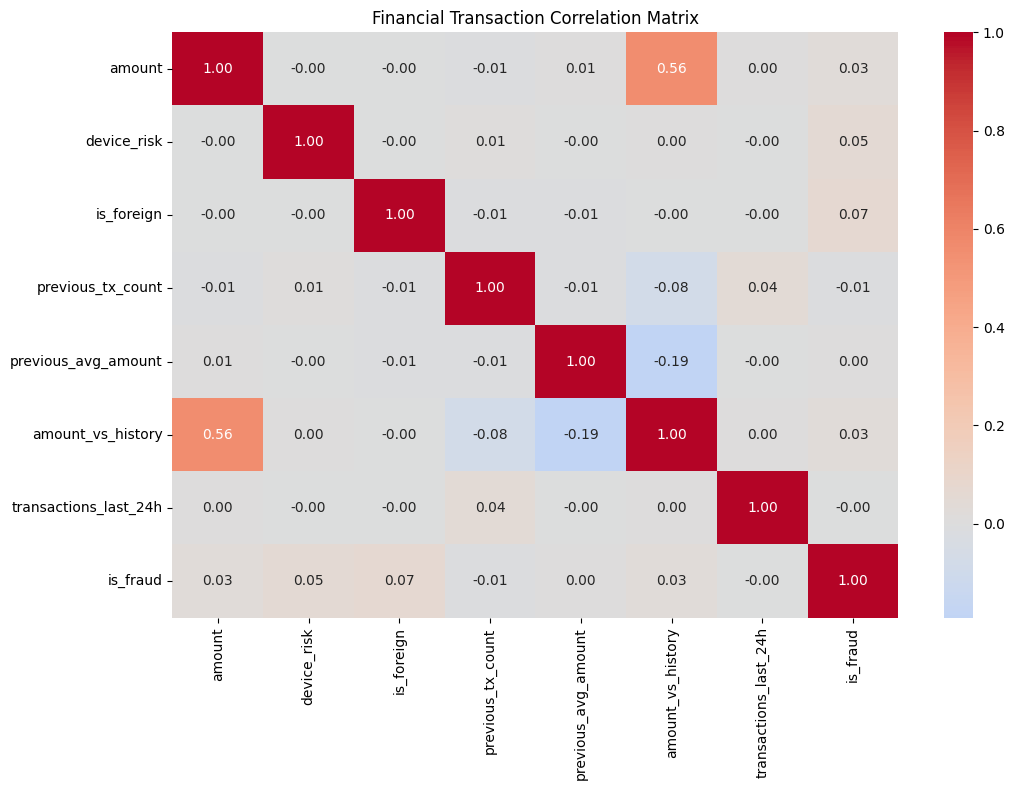

In [38]:

numeric_features = [
    "amount",
    "device_risk",
    "is_foreign",
    "previous_tx_count",
    "previous_avg_amount",
    "amount_vs_history",
    "transactions_last_24h",
    "is_fraud"
]

corr = features[numeric_features].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Financial Transaction Correlation Matrix")
plt.tight_layout()
plt.show()


**Notes: **Pearson correlation measures linear relationships. A low correlation does not necessarily mean a feature is useless for machine learning, particularly when the relationship is nonlinear or depends on interactions with other variables.

**Diagram 6 — Customer transaction behavior**

We'll compare customers by transaction count and total spending.

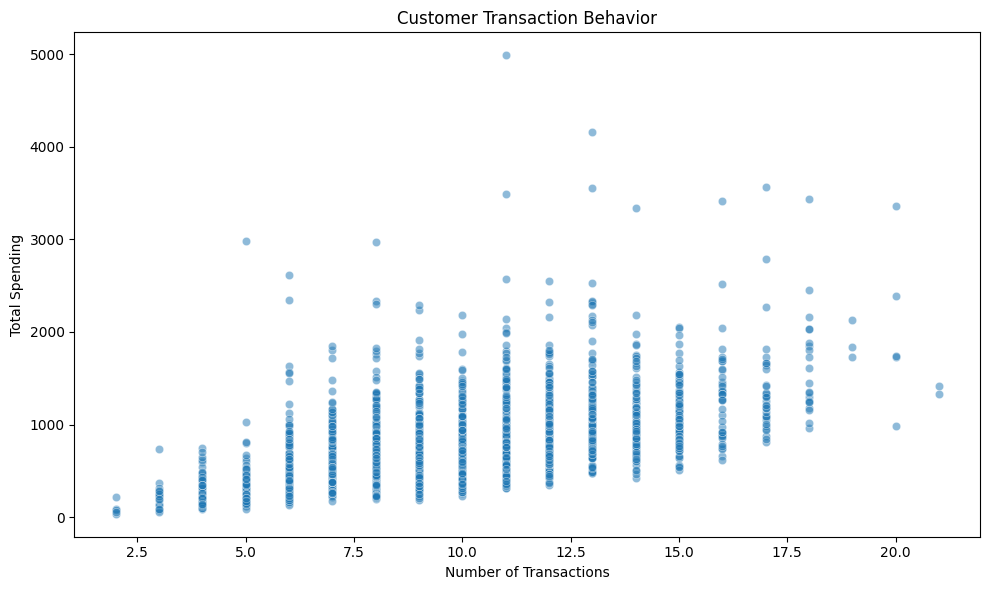

In [39]:

customer_summary = (
    features.groupby("customer_id")
    .agg(
        transactions=("transaction_id", "count"),
        total_spending=("amount", "sum"),
        average_amount=("amount", "mean")
    )
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=customer_summary,
    x="transactions",
    y="total_spending",
    alpha=0.5
)

plt.title("Customer Transaction Behavior")
plt.xlabel("Number of Transactions")
plt.ylabel("Total Spending")
plt.tight_layout()
plt.show()


**Notes:** This chart helps identify high-activity and high-value customers. In real banking data, unusual changes relative to a customer's historical behavior may be more informative than high spending by itself.

**Diagram 7 — Xarray fraud risk heatmap**

This visualization uses the Xarray data cube to compare countries and merchant categories.

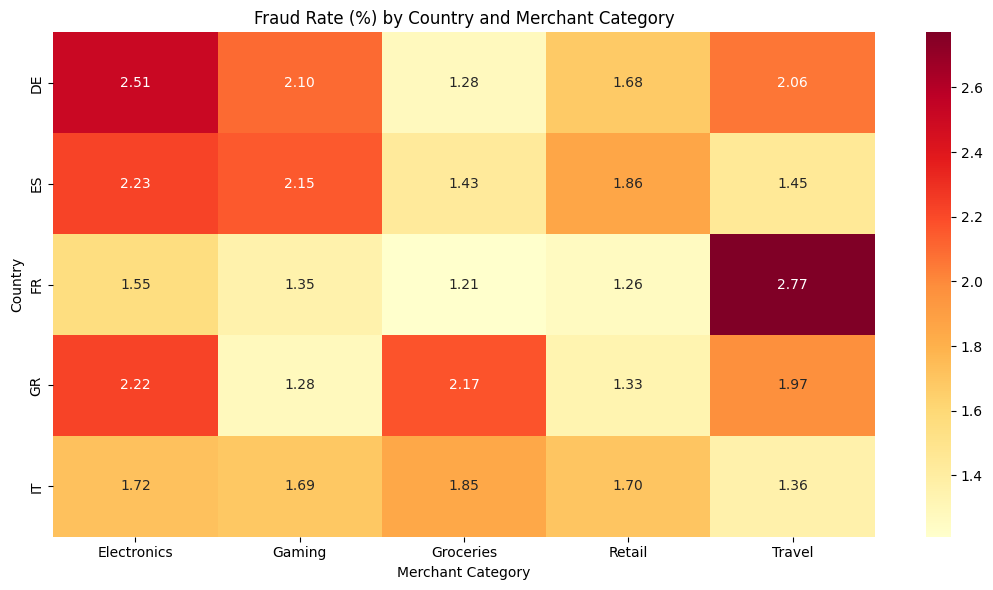

In [40]:

fraud_cases = cube["fraud_cases"].sum(dim="month")
transaction_counts = cube["transactions"].sum(dim="month")

risk_matrix = xr.where(
    transaction_counts > 0,
    fraud_cases / transaction_counts * 100,
    np.nan
)

risk_df = risk_matrix.to_pandas()

plt.figure(figsize=(11, 6))

sns.heatmap(
    risk_df,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd"
)

plt.title("Fraud Rate (%) by Country and Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


**Notes: **This is a practical example of using Xarray to reduce a three-dimensional dataset into a two-dimensional visualization. Small groups may produce unstable fraud rates, so inspect transaction counts alongside percentages.

**Diagram 8 — Fraud detection machine learning workflow**

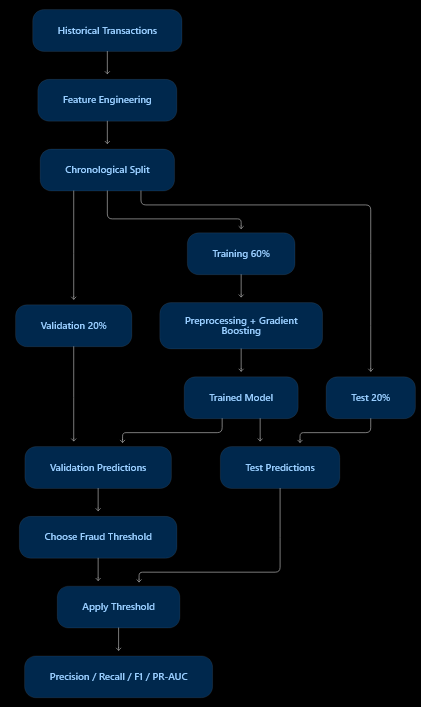

**Notes:** The validation dataset is used to choose the decision threshold. The test dataset is reserved for final evaluation. Repeatedly changing the model based on test results can make the reported performance overly optimistic.

**Diagram 9 — ROC curve**

The ROC curve shows the tradeoff between true-positive rate and false-positive rate across different classification thresholds.

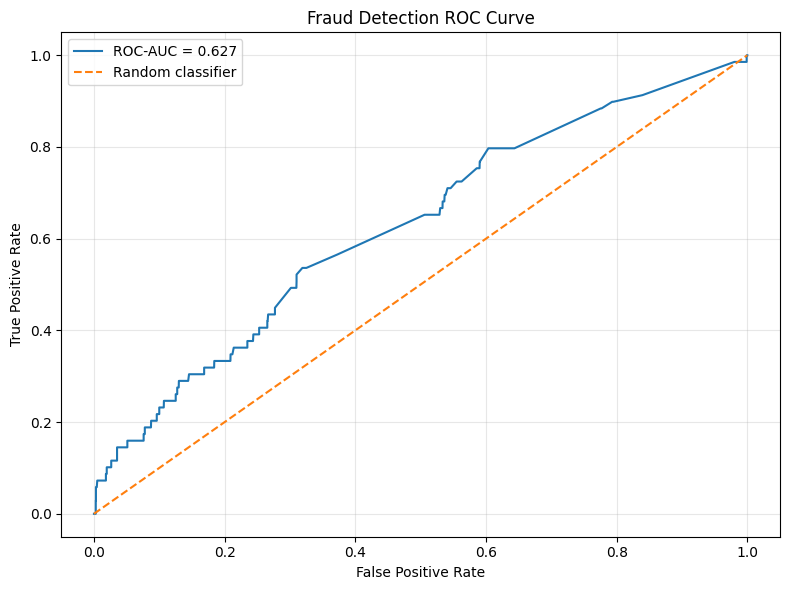

In [42]:
from sklearn.metrics import roc_curve, roc_auc_score

# Fix: Use 'probabilities' which contains the predicted probabilities from the model
fpr, tpr, _ = roc_curve(
    test["is_fraud"],
    probabilities
)

auc_score = roc_auc_score(
    test["is_fraud"],
    probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {auc_score:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Fraud Detection ROC Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Notes: **ROC-AUC measures ranking quality across thresholds. In highly imbalanced fraud datasets, also examine the precision-recall curve and the absolute number of false alerts.

**Diagram 10 — Fraud probability distribution**

This chart shows how predicted fraud probabilities differ between legitimate and fraudulent transactions.

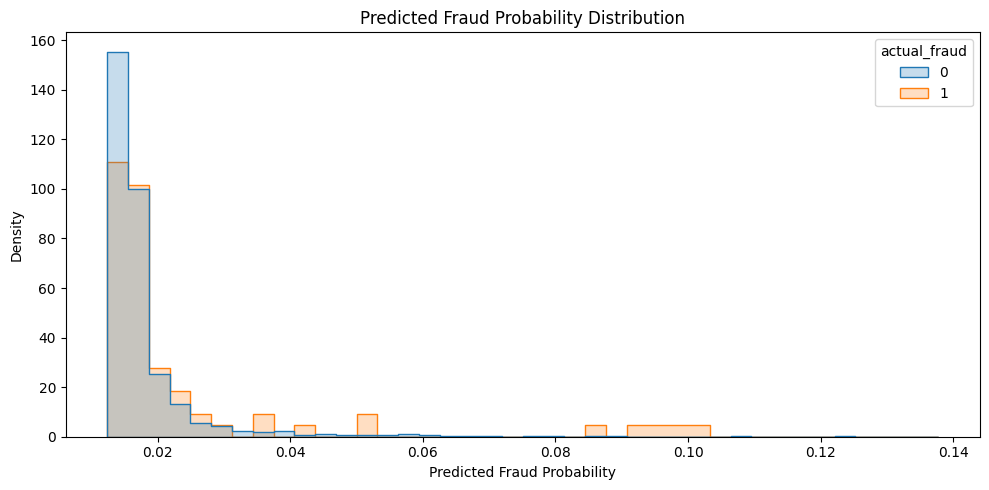

In [44]:

probability_df = pd.DataFrame({
    "fraud_probability": probabilities,
    "actual_fraud": test["is_fraud"].to_numpy()
})

plt.figure(figsize=(10, 5))

sns.histplot(
    data=probability_df,
    x="fraud_probability",
    hue="actual_fraud",
    bins=40,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Predicted Fraud Probability Distribution")
plt.xlabel("Predicted Fraud Probability")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

**Notes:** Ideally, fraudulent transactions receive higher scores than legitimate transactions. However, the distributions often overlap, and a predicted probability should not automatically be treated as a well-calibrated probability without calibration testing.

**Diagram 11 — Feature importance with permutation importance**

Let's identify which input features contribute most to model performance.

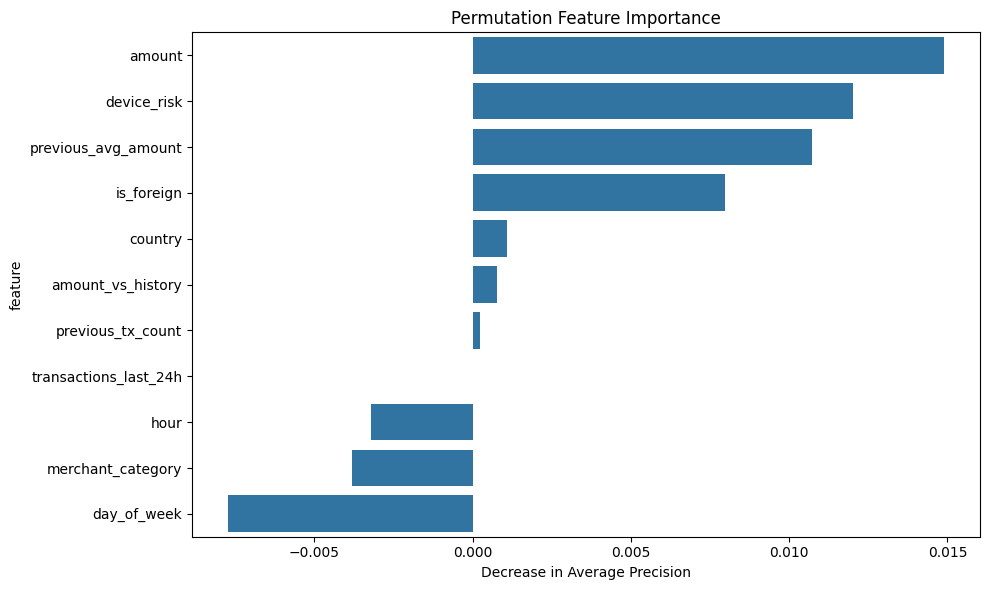

,feature,importance
0,amount,0.014896
2,device_risk,0.012016
4,previous_avg_amount,0.010734
1,is_foreign,0.007986
9,country,0.001081
5,amount_vs_history,0.000778
3,previous_tx_count,0.000224
6,transactions_last_24h,0.000000
7,hour,-0.003223
10,merchant_category,-0.003823


In [45]:

from sklearn.inspection import permutation_importance

# Use a manageable test sample for Colab
sample_size = min(3000, len(test))

X_sample = test[feature_cols].iloc[:sample_size]
y_sample = test["is_fraud"].iloc[:sample_size]

importance = permutation_importance(
    model,
    X_sample,
    y_sample,
    scoring="average_precision",
    n_repeats=3,
    random_state=RANDOM_STATE
)

importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": importance.importances_mean
}).sort_values("importance", ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="importance",
    y="feature"
)

plt.title("Permutation Feature Importance")
plt.xlabel("Decrease in Average Precision")
plt.tight_layout()
plt.show()

display(importance_df)


**Notes:** Permutation importance measures how much model performance changes when one feature is shuffled. It is not a measure of causation. Results may also be unstable for small test samples or strongly correlated features.

**Diagram 12 — Risk score distribution by customer**

We can aggregate transaction risk scores into a customer-level risk monitoring view.

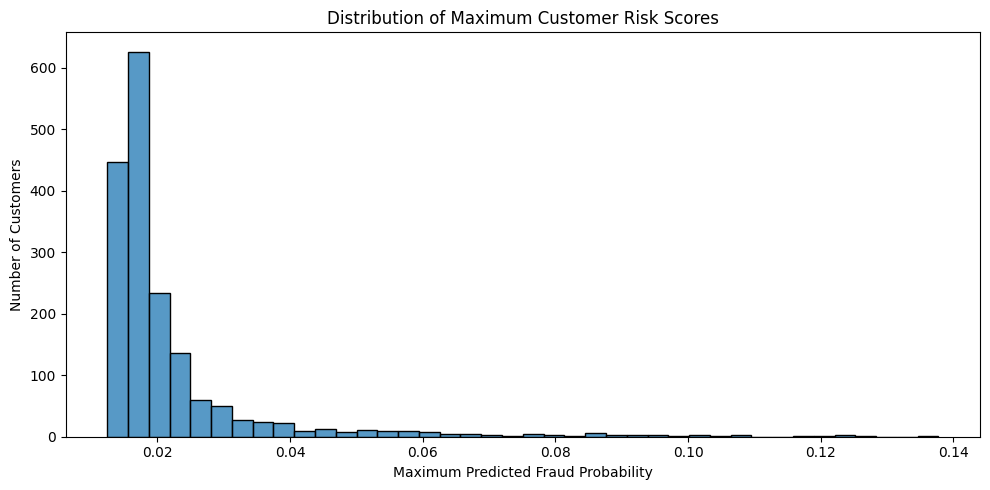

In [47]:

risk_results = test[[
    "customer_id",
    "transaction_id"
]].copy()

# Fix: Use 'probabilities' instead of the undefined 'test_probs'
risk_results["risk_score"] = probabilities

customer_risk = (
    risk_results.groupby("customer_id")
    .agg(
        transactions=("transaction_id", "count"),
        average_risk=("risk_score", "mean"),
        maximum_risk=("risk_score", "max")
    )
)

plt.figure(figsize=(10, 5))

sns.histplot(
    customer_risk["maximum_risk"],
    bins=40
)

plt.title("Distribution of Maximum Customer Risk Scores")
plt.xlabel("Maximum Predicted Fraud Probability")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

**Notes:** A maximum transaction score can highlight customers with at least one unusual transaction, but it is sensitive to transaction count. Customers with more transactions have more opportunities to receive an extreme score.

**Summary — What each visualization tells you**

•	Diagram Business question answered

•	Architecture    How does data move through the system?

•	Monthly volume  How is transaction activity changing?

•	Merchant fraud  Which categories have higher observed fraud rates?

•	Hourly fraud    Are there time-of-day patterns?

•	Correlation Which numerical variables move together?

•	Customer behavior   Which customers have unusual activity or spending?

•	Xarray heatmap  How does fraud vary across countries and categories?

•	ML workflow How is the model trained and evaluated?

•	ROC curve   How well does the model separate fraud from legitimate transactions?

•	Probability distribution    How do predicted risk scores overlap?

•	Feature importance  Which features influence model predictions?

•	Customer risk   How are transaction-level risks distributed across customers?


You can copy these additional cells into your existing Google Colab notebook after the model evaluation steps. They reuse the data and variables already created, so you do not need to regenerate the dataset.

The most valuable next improvement would be a Streamlit or Plotly interactive dashboard with country filters, merchant category selection, date ranges, fraud KPIs, customer risk tables, and model monitoring.

